In [2]:
# Day 3


# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Sklearn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Other Libraries
import random
import copy
import joblib
import os


In [3]:
# Setting Random Seeds

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Dataset Path

dataset_path = "/content/drive/MyDrive/food_dataset"

train = pd.read_csv(dataset_path + "/train_prepared.csv")
test = pd.read_csv(dataset_path + "/test_prepared.csv")


# Loading Day 2 Preprocessor

model_path = "/content/drive/MyDrive/SmartFood_Rescue/models"

preprocessor = joblib.load(
    model_path + "/preprocessor.pkl"
)


print("Training Shape:", train.shape)
print("Testing Shape:", test.shape)

print("Preprocessor Loaded Successfully!")

Training Shape: (456548, 18)
Testing Shape: (32573, 17)
Preprocessor Loaded Successfully!


In [6]:
# Sorted Unique Weeks

weeks = sorted(train["week"].unique())

split_index = int(len(weeks) * 0.8)

split_week = weeks[split_index]

# Splitting Data

train_data = train[train["week"] < split_week]

val_data = train[train["week"] >= split_week]


print("Split Week:", split_week)

print("Training Shape:", train_data.shape)
print("Validation Shape:", val_data.shape)

Split Week: 117
Training Shape: (361348, 18)
Validation Shape: (95200, 18)


In [12]:
low_threshold = train_data["num_orders"].quantile(0.33)
high_threshold = train_data["num_orders"].quantile(0.66)

print("Low Threshold: ", low_threshold)
print("High Threshold: ", high_threshold)

# Creating Demand Categories

def classify_demand(orders):
  if orders <= low_threshold:
    return 0
  elif orders <= high_threshold:
    return 1
  else:
    return 2

# Applying Classification

y_train = train_data["num_orders"].apply(classify_demand)
y_val = val_data["num_orders"].apply(classify_demand)

# Check Distributions

print("\nTraining Distributions: ")
print(y_train.value_counts().sort_index())

print("\nValidation Distributions: ")
print(y_val.value_counts().sort_index())

Low Threshold:  80.0
High Threshold:  243.0

Training Distributions: 
num_orders
0    124544
1    115646
2    121158
Name: count, dtype: int64

Validation Distributions: 
num_orders
0    33167
1    32220
2    29813
Name: count, dtype: int64


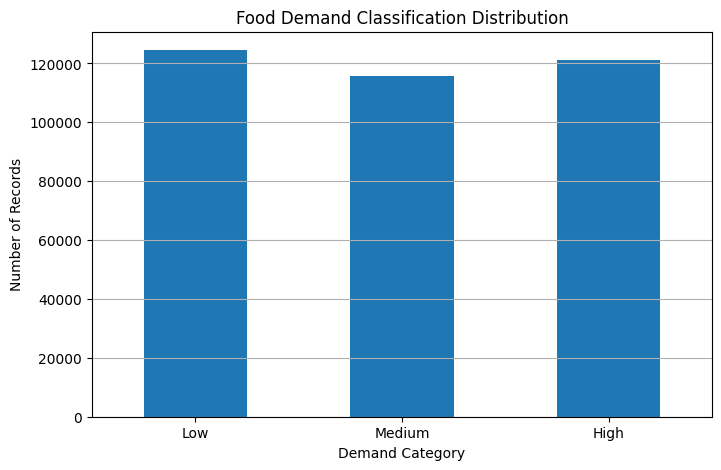

In [13]:
plt.figure(figsize=(8, 5))

y_train.value_counts().sort_index().plot(kind="bar")

plt.xticks(
    [0, 1, 2],
    ["Low", "Medium", "High"],
    rotation=0
)

plt.xlabel("Demand Category")
plt.ylabel("Number of Records")
plt.title("Food Demand Classification Distribution")

plt.grid(axis="y")
plt.show()

In [14]:
# Separating Input Features

X_train = train_data.drop(columns=["id", "num_orders"])
X_val = val_data.drop(columns=["id", "num_orders"])
X_test = test.drop(columns=["id"])


# Applying Existing Preprocessor

X_train_processed = preprocessor.transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [20]:
if hasattr(X_train_processed, "toarray"):
  X_train_processed = X_train_processed.toarray()

if hasattr(X_val_processed, "toarray"):
  X_val_processed = X_val_processed.toarray()

if hasattr(X_test_processed, "toarray"):
  X_test_processed = X_test_processed.toarray()

X_train_processed = X_train_processed.astype(np.float32)
X_val_processed = X_val_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

X_train_tensor = torch.tensor(X_train_processed)
X_val_tensor = torch.tensor(X_val_processed)
X_test_tensor = torch.tensor(X_test_processed)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.long)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.long)

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)

print("X_val:", X_val_tensor.shape)
print("y_val:", y_val_tensor.shape)


X_train: torch.Size([361348, 217])
y_train: torch.Size([361348])
X_val: torch.Size([95200, 217])
y_val: torch.Size([95200])


In [22]:

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

g = torch.Generator()
g.manual_seed(42)

# Creating DataLoaders

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, generator=g)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, generator=g)
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))

Training Batches: 1412
Validation Batches: 372


In [24]:
# Build ANN CLassification Model

class ANNClassifier(nn.Module):
  def __init__(self):
    super(ANNClassifier, self).__init__()

    self.model = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], 128),
        nn.ReLU(),

        nn.Linear(128, 64),
        nn.ReLU(),

        nn.Linear(64, 3)
    )

  def forward(self, x):
    return self.model(x)

In [25]:
# Initializing The Model
classifier = ANNClassifier()
print(classifier)

ANNClassifier(
  (model): Sequential(
    (0): Linear(in_features=217, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [26]:
# Loss Function And Optimizer

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(classifier.parameters(), lr=0.001)

In [28]:
print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [30]:
# Training the ANN Classifier Model

epochs = 100
patience = 10

best_val_loss = float("inf")
best_model = copy.deepcopy(classifier.state_dict())

counter = 0

train_losses = []
val_losses = []

for epoch in range(epochs):
  classifier.train()

  running_loss = 0.0

  for xb, yb in train_loader:
    optimizer.zero_grad()
    outputs = classifier(xb)
    loss = criterion(outputs, yb)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

  train_loss = running_loss / len(train_loader)

  # Validation

  classifier.eval()

  running_loss = 0.0

  with torch.no_grad():
    for xb, yb in val_loader:
      outputs = classifier(xb)
      loss = criterion(outputs, yb)
      running_loss += loss.item()

    val_loss = running_loss / len(val_loader)

  train_losses.append(train_loss)
  val_losses.append(val_loss)


  # Saving The Best Model

  if val_loss < best_val_loss - 0.0001:
    best_val_loss = val_loss
    best_model = copy.deepcopy(classifier.state_dict())
    counter = 0
  else:
    counter += 1

  print(f"Epoch = {epoch+1}/{epochs}, Training Loss = {train_loss}, Validation Loss = {val_loss}")

  # Early Stopping

  if counter >= patience:
    print("Early Stopping Triggered!")
    break

# Loading Best Model

classifier.load_state_dict(best_model)

print("\nTraining Completed!")
print("\nBest Validation Loss = ", best_val_loss)

Epoch = 1/100, Training Loss = 0.4922150207562082, Validation Loss = 0.5340289758738651
Epoch = 2/100, Training Loss = 0.4755801593320228, Validation Loss = 0.5313956234403836
Epoch = 3/100, Training Loss = 0.46892905011562047, Validation Loss = 0.5298974634178223
Epoch = 4/100, Training Loss = 0.46482321691749456, Validation Loss = 0.5328745307621136
Epoch = 5/100, Training Loss = 0.46122140728633737, Validation Loss = 0.5253175775049835
Epoch = 6/100, Training Loss = 0.45815311175990037, Validation Loss = 0.5274184185170359
Epoch = 7/100, Training Loss = 0.45559741050089386, Validation Loss = 0.5273550797694473
Epoch = 8/100, Training Loss = 0.45340585955563756, Validation Loss = 0.5321823018853382
Epoch = 9/100, Training Loss = 0.4512745889151738, Validation Loss = 0.528138363793973
Epoch = 10/100, Training Loss = 0.44935205154564156, Validation Loss = 0.5243345624016177
Epoch = 11/100, Training Loss = 0.44723303641374657, Validation Loss = 0.5276394124313067
Epoch = 12/100, Trainin

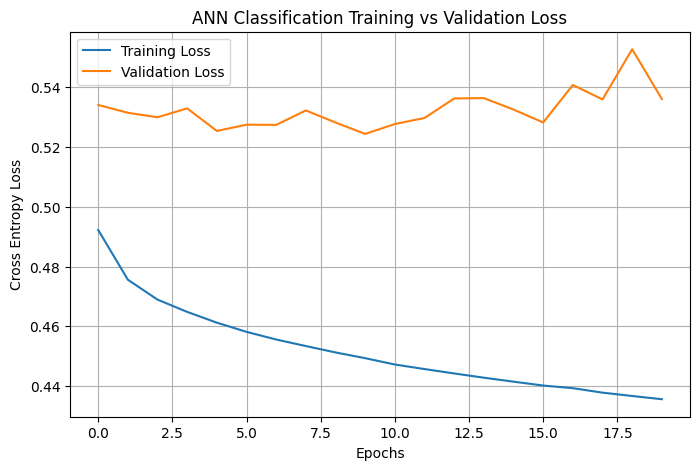

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("ANN Classification Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Cross Entropy Loss")

plt.legend()
plt.grid()

plt.show()


In [32]:
classifier.eval()

y_pred = []
y_actual = []

with torch.no_grad():
    for xb, yb in val_loader:
        outputs = classifier(xb)
        predictions = torch.argmax(outputs, dim=1)

        y_pred.extend(predictions.cpu().numpy())
        y_actual.extend(yb.cpu().numpy())

print("Predictions Completed!")
print("Total Predictions:", len(y_pred))

Predictions Completed!
Total Predictions: 95200


In [33]:
print("Accuracy:", accuracy_score(y_actual, y_pred))
print("Precision:", precision_score(y_actual, y_pred, average="macro"))
print("Recall:", recall_score(y_actual, y_pred, average="macro"))
print("F1 Score:", f1_score(y_actual, y_pred, average="macro"))

print("\nClassification Report:")

print(classification_report(
    y_actual,
    y_pred,
    target_names=["Low", "Medium", "High"]
))

Accuracy: 0.7672689075630252
Precision: 0.7778055705404059
Recall: 0.7679727320299868
F1 Score: 0.7712801300069204

Classification Report:
              precision    recall  f1-score   support

         Low       0.84      0.78      0.81     33167
      Medium       0.64      0.73      0.68     32220
        High       0.85      0.80      0.82     29813

    accuracy                           0.77     95200
   macro avg       0.78      0.77      0.77     95200
weighted avg       0.78      0.77      0.77     95200



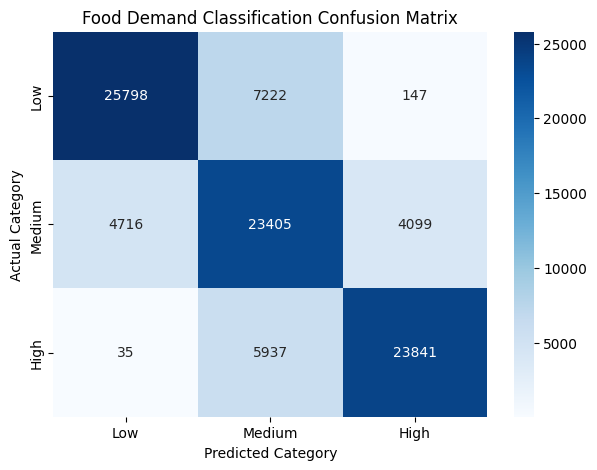

In [34]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_actual, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Food Demand Classification Confusion Matrix")

plt.show()

In [35]:
import os
import joblib

model_path = "/content/drive/MyDrive/SmartFood_Rescue/models"

os.makedirs(model_path, exist_ok=True)

torch.save(
    classifier.state_dict(),
    model_path + "/ann_classifier.pth"
)

print("ANN Classifier Saved Successfully!")

ANN Classifier Saved Successfully!


In [36]:
thresholds = {
    "low_threshold": low_threshold,
    "high_threshold": high_threshold,
    "class_mapping": {
        0: "Low",
        1: "Medium",
        2: "High"
    }
}

joblib.dump(
    thresholds,
    model_path + "/demand_thresholds.pkl"
)

print("Demand Thresholds Saved Successfully!")

Demand Thresholds Saved Successfully!


In [37]:
print("Saved Model Files:")

for file in os.listdir(model_path):
    print(file)

Saved Model Files:
ann_regressor.pth
preprocessor.pkl
ann_classifier.pth
demand_thresholds.pkl


In [38]:
# Making Test Predictions

classifier.eval()

test_predictions = []

with torch.no_grad():
    for i in range(0, len(X_test_tensor), 256):
        xb = X_test_tensor[i:i+256]
        outputs = classifier(xb)
        predictions = torch.argmax(outputs, dim=1)
        test_predictions.extend(predictions.cpu().numpy())

print("Test Predictions Completed!")
print("Total Predictions:", len(test_predictions))

Test Predictions Completed!
Total Predictions: 32573


In [39]:
# Creating Predictions DataFrame

prediction_df = pd.DataFrame({
    "id": test["id"],
    "predicted_demand": test_predictions
})

# Converting numerical labels into categorical names

prediction_df["predicted_demand"] = prediction_df["predicted_demand"].map({
    0: "Low",
    1: "Medium",
    2: "High"
})

print(prediction_df.head())
print("\nTotal Records:", len(prediction_df))

        id predicted_demand
0  1028232           Medium
1  1127204           Medium
2  1212707           Medium
3  1082698              Low
4  1400926              Low

Total Records: 32573


In [40]:
# Creating Predictions Folder

prediction_path = "/content/drive/MyDrive/SmartFood_Rescue/predictions"

os.makedirs(prediction_path, exist_ok=True)

# Saving Predictions

prediction_df.to_csv(
    prediction_path + "/food_demand_predictions.csv",
    index=False
)

print("Prediction CSV Saved Successfully!")

Prediction CSV Saved Successfully!


In [41]:
print("Demand Prediction Distribution:")
print(prediction_df["predicted_demand"].value_counts())

print("\nTotal Predictions:", len(prediction_df))
print("\nMissing Values:")
print(prediction_df.isnull().sum())

Demand Prediction Distribution:
predicted_demand
Medium    13524
Low        9953
High       9096
Name: count, dtype: int64

Total Predictions: 32573

Missing Values:
id                  0
predicted_demand    0
dtype: int64


In [42]:
prediction_file = prediction_path + "/food_demand_predictions.csv"

print("File Exists:", os.path.exists(prediction_file))

print("\nSaved File:")
print(prediction_file)

print("\nPrediction Preview:")
print(pd.read_csv(prediction_file).head())


File Exists: True

Saved File:
/content/drive/MyDrive/SmartFood_Rescue/predictions/food_demand_predictions.csv

Prediction Preview:
        id predicted_demand
0  1028232           Medium
1  1127204           Medium
2  1212707           Medium
3  1082698              Low
4  1400926              Low
